# Solutions to the exercises of Chapter 11

Sample solutions for [Chapter 11, Swelling and squeezing of a gel](../../notebooks/part3_soft_materials/11_gel_swelling.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.optimize import brentq, least_squares

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. Times in practice

In the units of the chapter, times are measured in $fh^2/K$ (sheet) or $fa^2/K$
(sphere). With $D = M/f$, the unit is $(M/K)\,h^2/D$. For $G/K = 0.6$, $M/K = 1.8$.

In [2]:
D, g = 1e-11, 0.6
MK = 1 + 4 * g / 3
L = 0.5e-3
unit = MK * L**2 / D                                   # f L^2 / K in seconds

t_sheet = brentq(lambda t: on.gel_sheet_series(np.array([1.0]), t, g)[0] - 0.9, 1e-4, 10)
t_sphere = brentq(lambda t: on.gel_sphere_series(np.array([1.0]), t, g)[0] - 0.9, 1e-4, 10)
n = np.arange(1, 400)
s_tf = brentq(lambda s: 1 - np.sum(6 / (n * np.pi) ** 2 * np.exp(-(n * np.pi) ** 2 * s)) - 0.9, 1e-4, 10)
print(f"(a) sheet 0.5 mm on glass:   90 % after {t_sheet:.4f} f h^2/K = {t_sheet * unit / 3600:.2f} h")
print(f"(b) free sphere, a = 0.5 mm: 90 % after {t_sphere:.4f} f a^2/K = {t_sphere * unit / 3600:.2f} h")
print(f"(c) Tanaka-Fillmore (11.14) with D = 1e-11 m^2/s: Dt/a^2 = {s_tf:.4f}  ->  {s_tf * L**2 / D / 3600:.2f} h")

(a) sheet 0.5 mm on glass:   90 % after 0.4712 f h^2/K = 5.89 h
(b) free sphere, a = 0.5 mm: 90 % after 0.1722 f a^2/K = 2.15 h
(c) Tanaka-Fillmore (11.14) with D = 1e-11 m^2/s: Dt/a^2 = 0.1830  ->  1.27 h


The sheet takes almost three times as long as the sphere of the same size. In both
the solvent must flow a distance of order $L$, but the sheet takes in solvent through
one face only, while the sphere takes it in from all sides. Tanaka and Fillmore's
formula, used with the light-scattering $D = M/f$, gives a time 40 % too short for the
sphere: it assumes that the rate is set by $M$, when it is set mainly by $K$.

## Exercise 2. Squeezing

(a) From Eq. (11.10) with Eq. (11.8), the pressure at the base, $z = 0$, is

$$ \frac{p(0,t)}{P} = 1 - \frac{\partial u}{\partial z}\Big|_{z = 0} = \sum_{k=0}^\infty\frac{4\,(-1)^k}{m\pi}\,e^{-(M/K)m^2\pi^2t/4} . $$

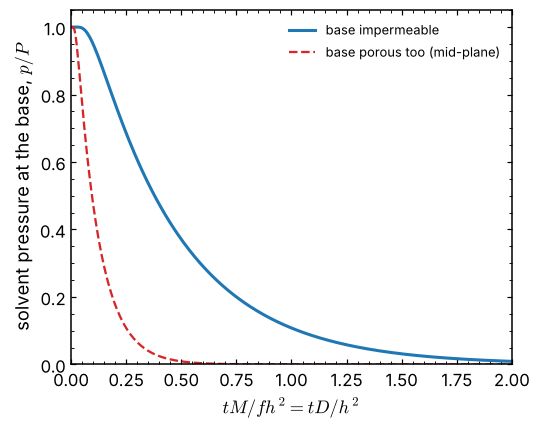

tD/h^2 = 0.05:  p(base)/P = 0.9969
tD/h^2 = 0.20:  p(base)/P = 0.7723
tD/h^2 = 0.50:  p(base)/P = 0.3708
tD/h^2 = 1.00:  p(base)/P = 0.1080


In [3]:
def base_pressure(t, n_terms=2000):
    k = np.arange(n_terms)
    m = 2 * k + 1
    return np.sum(4 * (-1) ** k / (m * np.pi) * np.exp(-(m * np.pi / 2) ** 2 * t))   # t in units f h^2 / M

tM = np.linspace(0.0005, 2.0, 400)
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.plot(tM, [base_pressure(s) for s in tM], "C0", lw=2, label="base impermeable")
ax.plot(tM, [base_pressure(4 * s) for s in tM], "C3--", lw=1.5, label="base porous too (mid-plane)")
ax.set_xlabel(r"$tM/fh^2 = tD/h^2$"); ax.set_ylabel(r"solvent pressure at the base, $p/P$")
ax.set_xlim(0, 2); ax.set_ylim(0, 1.05); ax.legend(loc="upper right", fontsize=8.5)
plt.show()
for s in (0.05, 0.2, 0.5, 1.0):
    print(f"tD/h^2 = {s:4.2f}:  p(base)/P = {base_pressure(s):.4f}")

**Figure S11.1.** Pressure of the solvent at the impermeable base of a squeezed sheet.
It stays at the full load until the drainage, which starts at the piston, reaches the
base at $tD/h^2 \approx 0.05$.

(b) The load $P$ is constant, so the piston does the work $P\,\delta_\infty$, with the final
settlement $\delta_\infty = h\varepsilon_\infty = Ph/M$. The network stores $\tfrac12M\varepsilon_\infty^2h = \tfrac12P\delta_\infty$.
The rest, the other half, is dissipated by the solvent flowing through the network,
just as half of the work of the wall was dissipated in the capillary rise of
Chapter 6. The dissipation, $\int\!\int f\dot u^2\,dz\,dt$, is computed below from the series
in the units of the chapter (displacements in $\delta_\infty$, $K = f = h = 1$), where the
work is $M/K$ and the stored energy $M/2K$.

In [4]:
def u_dot(z, t, n_terms=400):
    k = np.arange(n_terms)[:, None]
    m = 2 * k + 1
    q = m * np.pi / 2
    return np.sum((-1) ** k * 8 / (m * np.pi) ** 2 * MK * q**2 * np.sin(q * z) * np.exp(-MK * q**2 * t), axis=0)

zq, wq = np.polynomial.legendre.leggauss(200); zq, wq = 0.5 * (zq + 1), 0.5 * wq
times = np.concatenate((np.logspace(-7, -2, 400), np.linspace(0.0101, 4, 800)))
rate = np.array([np.sum(wq * u_dot(zq, s) ** 2) for s in times])
dissipated = np.trapezoid(rate, times)
print(f"work by the load {MK:.4f},  stored {MK / 2:.4f},  dissipated {dissipated:.4f}  (from the series)")

work by the load 1.8000,  stored 0.9000,  dissipated 0.9003  (from the series)


The small difference from $M/2K = 0.9$ comes from the very first instants, where the
rate of dissipation diverges as $t^{-1/2}$ and the quadrature misses a little of it.

(c) If the base is porous too, the solvent leaves through both faces. By symmetry
the mid-plane acts as an impermeable base for each half, so the problem is that of
a sheet of thickness $h/2$: every time is divided by four (dashed curve in
Figure S11.1).

## Exercise 3. The sphere in detail

(a) With $u = j_1(\alpha r)$ (radius $a = 1$), the divergence is $\theta = \alpha\,j_0(\alpha r)$, since
$(x^2j_1)' = x^2j_0$, and $\partial_r\theta = -\alpha^2j_1(\alpha r)$. So $D\,\partial_r\theta = -D\alpha^2u$, which is
$\partial u/\partial t$ for a mode decaying at the rate $D\alpha^2$. The deviation from the final state
obeys the homogeneous form of Eq. (11.12), $M\theta - 4Gu = 0$ at $r = 1$:

In [5]:
x, ratio_GM = sp.symbols("alpha G_over_M", positive=True)
j0 = sp.sin(x) / x
j1 = sp.sin(x) / x**2 - sp.cos(x) / x
rr = sp.symbols("r", positive=True)
u_mode = j1.subs(x, x * rr)
theta = sp.simplify(sp.diff(rr**2 * u_mode, rr) / rr**2)
print("theta - alpha j0(alpha r) =", sp.simplify(theta - x * j0.subs(x, x * rr)))
print("d theta/dr + alpha^2 u   =", sp.simplify(sp.diff(theta, rr) + x**2 * u_mode))
condition = sp.solve(sp.Eq(theta.subs(rr, 1), 4 * ratio_GM * u_mode.subs(rr, 1)), ratio_GM)[0]
print("G/M =", sp.simplify(condition), "  equals alpha^2/(4 - 4 alpha cot alpha):",
      sp.simplify(condition - x**2 / (4 - 4 * x * sp.cot(x))) == 0)

theta - alpha j0(alpha r) = 0
d theta/dr + alpha^2 u   = 0


G/M = -alpha**2*sin(alpha)/(4*alpha*cos(alpha) - 4*sin(alpha))   equals alpha^2/(4 - 4 alpha cot alpha): True


(b) For small $\alpha$, $\sin\alpha - \alpha\cos\alpha = \alpha^3/3 - \alpha^5/30 + \ldots$ and
$\alpha^2\sin\alpha = \alpha^3 - \alpha^5/6 + \ldots$. Writing Eq. (11.13) as
$4(G/M)(\sin\alpha - \alpha\cos\alpha) = \alpha^2\sin\alpha$ and $G/M = \tfrac34 - \delta$,

$$ \alpha^3\Big(\frac{4G}{3M} - 1\Big) + \alpha^5\Big(\frac16 - \frac{2G}{15M}\Big) = 0 \quad\Longrightarrow\quad -\frac43\delta + \frac{\alpha^2}{15} \approx 0 , \qquad \alpha_1^2 \approx 20\,\delta . $$

Since $\tfrac34 - G/M = \tfrac34K/M$, $\delta = 3K/4M$ and $M\alpha_1^2 \to 15K$: the exact slowest rate becomes
$15K/fa^2$, the rate of the uniform dilation. The cell checks it; the approach is
as $1/G$.

In [6]:
for gg in (1, 10, 100, 1000, 1e4):
    lam = (1 + 4 * gg / 3) * on.gel_sphere_roots(gg, 1)[0] ** 2
    print(f"G/K = {gg:7g}:  M alpha_1^2 / K = {lam:.5f},   (15 - that) * G/K = {(15 - lam) * gg:.4f}")

G/K =       1:  M alpha_1^2 / K = 12.48097,   (15 - that) * G/K = 2.5190
G/K =      10:  M alpha_1^2 / K = 14.55752,   (15 - that) * G/K = 4.4248
G/K =     100:  M alpha_1^2 / K = 14.95221,   (15 - that) * G/K = 4.7787
G/K =    1000:  M alpha_1^2 / K = 14.99518,   (15 - that) * G/K = 4.8171
G/K =   10000:  M alpha_1^2 / K = 14.99952,   (15 - that) * G/K = 4.8216


## Exercise 4. Reading a swelling experiment

The cell fits Tanaka and Fillmore's curve (11.14), with $\tau = a^2/\pi^2D_{\rm app}$, to the exact
swelling of a sphere between 5 % and 95 % of the final volume, for several $G/K$.

G/K =   0.0:  D_app = 1.000 K/f = 1.000 M/f,  rms misfit 0.0000
G/K =   0.1:  D_app = 0.989 K/f = 0.872 M/f,  rms misfit 0.0051


G/K =   0.3:  D_app = 0.973 K/f = 0.695 M/f,  rms misfit 0.0133


G/K =   0.6:  D_app = 0.958 K/f = 0.532 M/f,  rms misfit 0.0225
G/K =   1.0:  D_app = 0.946 K/f = 0.405 M/f,  rms misfit 0.0311


G/K =   3.0:  D_app = 0.925 K/f = 0.185 M/f,  rms misfit 0.0500


G/K =  10.0:  D_app = 0.914 K/f = 0.064 M/f,  rms misfit 0.0632


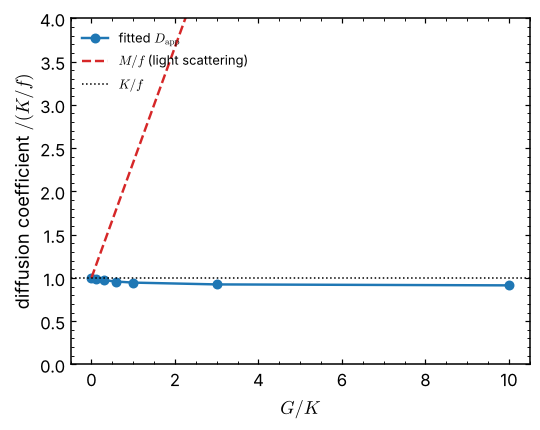

In [7]:
def tanaka_fillmore(s, n_terms=300):
    n = np.arange(1, n_terms + 1)[:, None]
    return 1 - np.sum(6 / (n * np.pi) ** 2 * np.exp(-(n * np.pi) ** 2 * np.atleast_1d(s)), axis=0)

rows = []
for gg in (0.0, 0.1, 0.3, 0.6, 1.0, 3.0, 10.0):
    t = np.linspace(0.0005, 0.35, 300)
    exact = on.gel_sphere_series(np.array([1.0]), t, gg)[:, 0]
    keep = (exact > 0.05) & (exact < 0.95)
    fit = least_squares(lambda d: tanaka_fillmore(d[0] * t[keep]) - exact[keep], [1.0])
    d_app = fit.x[0]                                    # D_app in units of K/f
    rows.append((gg, d_app))
    print(f"G/K = {gg:5.1f}:  D_app = {d_app:.3f} K/f = {d_app / (1 + 4 * gg / 3):.3f} M/f,"
          f"  rms misfit {np.sqrt(np.mean(fit.fun ** 2)):.4f}")

fig, ax = plt.subplots(figsize=(4.8, 3.8))
gg = np.array([r[0] for r in rows]); dd = np.array([r[1] for r in rows])
ax.plot(gg, dd, "C0o-", label=r"fitted $D_{\rm app}$")
ax.plot(gg, 1 + 4 * gg / 3, "C3--", label=r"$M/f$ (light scattering)")
ax.axhline(1, color="k", ls=":", lw=1, label=r"$K/f$")
ax.set_xlabel(r"$G/K$"); ax.set_ylabel(r"diffusion coefficient $/(K/f)$"); ax.set_ylim(0, 4)
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

**Figure S11.2.** The diffusion coefficient obtained by fitting Tanaka and Fillmore's
curve to the exact swelling of a sphere.

The fitted coefficient stays within 10 % of $K/f$ (it even falls slightly, to $0.91\,K/f$
at $G/K = 10$), while the true collective diffusion coefficient $M/f$ grows in
proportion to $G$. The fits are fair: the misfit is 0.02 for $G/K = 0.6$ and 0.06 for
$G/K = 10$, small enough to pass for experimental scatter. What a swelling experiment
on a sphere measures is therefore mainly $K/f$, the osmotic bulk modulus over the
friction, and it agrees with light scattering only when $G \ll K$. The fitted value is
not the slowest rate either ($\lambda_1/\pi^2$ rises from 1 to 1.5 in units of $K/f$): the fit is
dominated by the early and middle part of the swelling, where the sphere swells
from its surface. This is why Peters and Candau analysed the swelling
with the shear modulus included, and why a swelling experiment combined with light
scattering gives the ratio $G/K$.